In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/ancestry_project/data', exist_ok=True)
%cd /content/drive/MyDrive/ancestry_project/data

Mounted at /content/drive
/content/drive/MyDrive/ancestry_project/data


In [3]:
BASE = "http://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502"
!wget -nc {BASE}/ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
!wget -nc {BASE}/integrated_call_samples_v3.20130502.ALL.panel

--2026-11-07 06:31:08--  http://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
Resolving ftp.1000genomes.ebi.ac.uk (ftp.1000genomes.ebi.ac.uk)... 193.62.193.167
Connecting to ftp.1000genomes.ebi.ac.uk (ftp.1000genomes.ebi.ac.uk)|193.62.193.167|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 205612353 (196M) [application/x-gzip]
Saving to: ‘ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz’

ALL.chr22.phase3_sh 100%[===================>] 196.09M   360KB/s    in 4m 4s   

2026-11-07 06:35:12 (824 KB/s) - ‘ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz’ saved [205612353/205612353]

--2026-11-07 06:35:12--  http://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/integrated_call_samples_v3.20130502.ALL.panel
Resolving ftp.1000genomes.ebi.ac.uk (ftp.1000genomes.ebi.ac.uk)... 193.62.193.167
Connecting to ftp.1000genomes.ebi.ac.uk (ftp

In [4]:
import pandas as pd
panel = pd.read_csv("integrated_call_samples_v3.20130502.ALL.panel", sep="\t").iloc[:, :4]
print(panel.shape)                  # expect 2504 rows
print(panel['super_pop'].value_counts())   # AFR, AMR, EAS, EUR, SAS

(2504, 4)
super_pop
AFR    661
EAS    504
EUR    503
SAS    489
AMR    347
Name: count, dtype: int64


In [5]:
!apt-get -qq install plink1.9 > /dev/null

VCF = "ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz"

# 1) keep biallelic SNPs, MAF >= 5%, <2% missing
!plink1.9 --vcf {VCF} --double-id --snps-only just-acgt --biallelic-only strict \
  --maf 0.05 --geno 0.02 --make-bed --out chr22_filt

# 2) LD pruning (window 50 SNPs, step 5, r² < 0.2)
!plink1.9 --bfile chr22_filt --indep-pairwise 50 5 0.2 --out chr22_prune

# 3) keep pruned SNPs, export as 0/1/2 matrix
!plink1.9 --bfile chr22_filt --extract chr22_prune.prune.in --recode A --out chr22_final

PLINK v1.90b7.2 64-bit (11 Dec 2023)           www.cog-genomics.org/plink/1.9/
(C) 2005-2023 Shaun Purcell, Christopher Chang   GNU General Public License v3
Logging to chr22_filt.log.
Options in effect:
  --biallelic-only strict
  --double-id
  --geno 0.02
  --maf 0.05
  --make-bed
  --out chr22_filt
  --snps-only just-acgt
  --vcf ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz

12975 MB RAM detected; reserving 6487 MB for main workspace.
--vcf: chr22_filt-temporary.bed + chr22_filt-temporary.bim +
chr22_filt-temporary.fam written.
(6348 variants skipped.)
1055454 out of 1097199 variants loaded from .bim file.
2504 people (0 males, 0 females, 2504 ambiguous) loaded from .fam.
Ambiguous sex IDs written to chr22_filt.nosex .
Using 1 thread (no multithreaded calculations invoked).
Before main variant filters, 2504 founders and 0 nonfounders present.
Calculating allele frequencies... 0%1%2%3%4%5%6%7%8%9%10%11%12%13%14%15%16

In [6]:
import numpy as np
raw = pd.read_csv("chr22_final.raw", sep=r"\s+")
raw['sample'] = raw['IID'].str.split('_').str[-1]   # PLINK may prefix the ID; check yours
df = raw.merge(panel, on='sample' if 'sample' in panel.columns else None)

snp_cols = [c for c in raw.columns if c not in ['FID','IID','PAT','MAT','SEX','PHENOTYPE','sample']]
X = df[snp_cols].values            # 0/1/2 genotypes
y = df['super_pop'].values

# fill rare missing values with the SNP's most common value (or 0)
X = np.nan_to_num(X, nan=0)
np.save("X.npy", X); np.save("y.npy", y)
print(X.shape, pd.Series(y).value_counts())

(2504, 97216) AFR    661
EAS    504
EUR    503
SAS    489
AMR    347
Name: count, dtype: int64


**PCA**

In [2]:
from sklearn.model_selection import train_test_split

X = np.load("X.npy").astype(np.float32)
y = np.load("y.npy", allow_pickle=True)

# first take out 30%, then split that 30% half and half
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("Train:", X_train.shape, " Val:", X_val.shape, " Test:", X_test.shape)

Train: (1752, 97216)  Val: (376, 97216)  Test: (376, 97216)


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

N_COMPONENTS = 20

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

pca = PCA(n_components=N_COMPONENTS, random_state=42)
X_train_pc = pca.fit_transform(X_train_s)
X_val_pc = pca.transform(X_val_s)
X_test_pc = pca.transform(X_test_s)

print("Variance kept by 20 PCs: {:.1f}%".format(pca.explained_variance_ratio_.sum() * 100))

Variance kept by 20 PCs: 20.8%


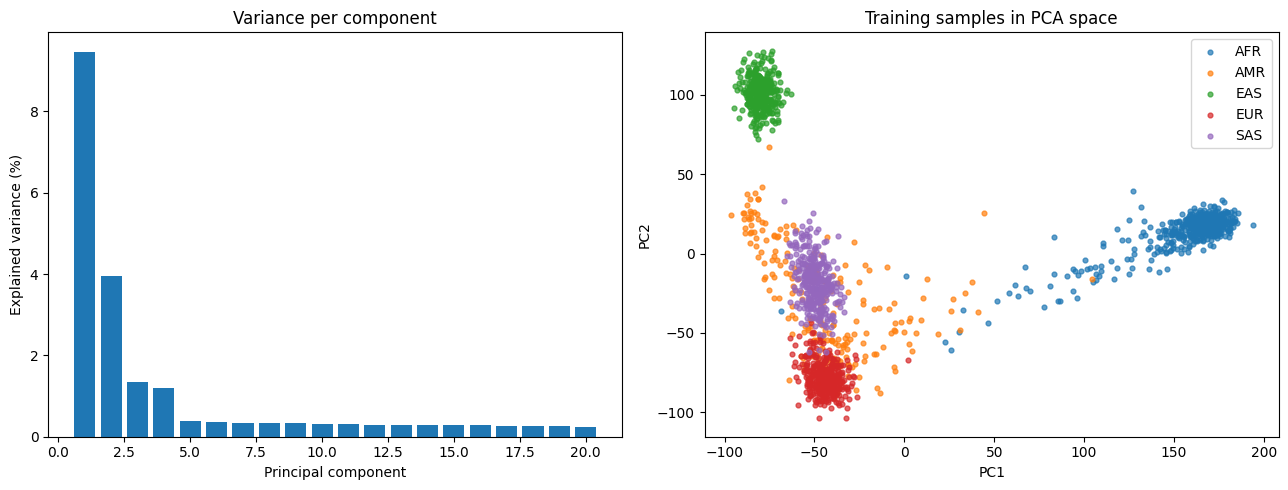

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# how much variance each component explains
axes[0].bar(range(1, N_COMPONENTS + 1), pca.explained_variance_ratio_ * 100)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance (%)")
axes[0].set_title("Variance per component")

# PC1 vs PC2 coloured by superpopulation
for group in np.unique(y_train):
    mask = y_train == group
    axes[1].scatter(X_train_pc[mask, 0], X_train_pc[mask, 1], s=12, label=group, alpha=0.7)
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("Training samples in PCA space")
axes[1].legend()

plt.tight_layout()
plt.show()

**Random Forest**

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid, cv=5, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train_pc, y_train)

rf = grid.best_estimator_
print("Best settings:", grid.best_params_)

rf_val_pred = rf.predict(X_val_pc)
print("RF validation accuracy: {:.4f}".format(accuracy_score(y_val, rf_val_pred)))
print("RF validation macro F1: {:.4f}".format(f1_score(y_val, rf_val_pred, average="macro")))

Best settings: {'max_depth': None, 'n_estimators': 200}
RF validation accuracy: 0.9814
RF validation macro F1: 0.9776


**ANN**

In [6]:
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder

tf.random.set_seed(42)

# the network needs numbers as labels, not strings
encoder = LabelEncoder()
y_train_n = encoder.fit_transform(y_train)
y_val_n = encoder.transform(y_val)
y_test_n = encoder.transform(y_test)
class_names = encoder.classes_
print("Classes:", class_names)


def build_ann(n_features, n_classes):
    model = keras.Sequential([
        keras.layers.Input(shape=(n_features,)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(n_classes, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


ann = build_ann(N_COMPONENTS, len(class_names))
ann.summary()

Classes: ['AFR' 'AMR' 'EAS' 'EUR' 'SAS']


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,589 (14.02 KB)

 Trainable params: 3,589 (14.02 KB)

 Non-trainable params: 0 (0.00 B)

Stopped after 68 epochs
ANN validation accuracy: 0.9761
ANN validation macro F1: 0.9704


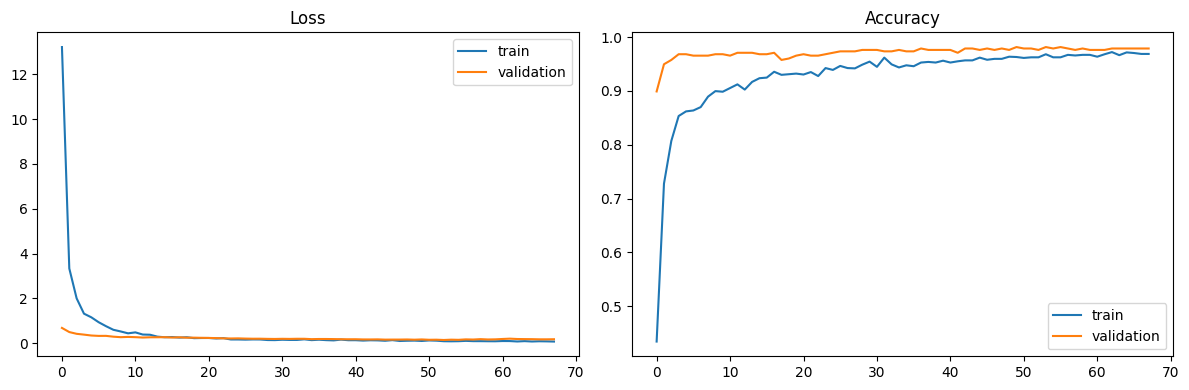

In [7]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True)

history = ann.fit(
    X_train_pc, y_train_n,
    validation_data=(X_val_pc, y_val_n),
    epochs=200, batch_size=32,
    callbacks=[early_stop], verbose=0)

print("Stopped after", len(history.history["loss"]), "epochs")

ann_val_pred = np.argmax(ann.predict(X_val_pc, verbose=0), axis=1)
print("ANN validation accuracy: {:.4f}".format(accuracy_score(y_val_n, ann_val_pred)))
print("ANN validation macro F1: {:.4f}".format(f1_score(y_val_n, ann_val_pred, average="macro")))

# training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

**Evaluation**

In [8]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

rf_test_pred = rf.predict(X_test_pc)
ann_test_pred = class_names[np.argmax(ann.predict(X_test_pc, verbose=0), axis=1)]

results = pd.DataFrame({
    "Model": ["Random Forest", "ANN"],
    "Accuracy": [accuracy_score(y_test, rf_test_pred), accuracy_score(y_test, ann_test_pred)],
    "Macro F1": [f1_score(y_test, rf_test_pred, average="macro"),
                 f1_score(y_test, ann_test_pred, average="macro")],
})
print(results.round(4).to_string(index=False))

print("\n--- Random Forest ---")
print(classification_report(y_test, rf_test_pred))
print("--- ANN ---")
print(classification_report(y_test, ann_test_pred))

        Model  Accuracy  Macro F1
Random Forest    0.9761    0.9705
          ANN    0.9681    0.9601

--- Random Forest ---
              precision    recall  f1-score   support

         AFR       0.98      1.00      0.99       100
         AMR       0.98      0.85      0.91        52
         EAS       1.00      1.00      1.00        75
         EUR       0.93      0.99      0.96        76
         SAS       1.00      1.00      1.00        73

    accuracy                           0.98       376
   macro avg       0.98      0.97      0.97       376
weighted avg       0.98      0.98      0.98       376

--- ANN ---
              precision    recall  f1-score   support

         AFR       0.99      0.99      0.99       100
         AMR       0.98      0.79      0.87        52
         EAS       1.00      1.00      1.00        75
         EUR       0.88      1.00      0.94        76
         SAS       1.00      1.00      1.00        73

    accuracy                           0.97     

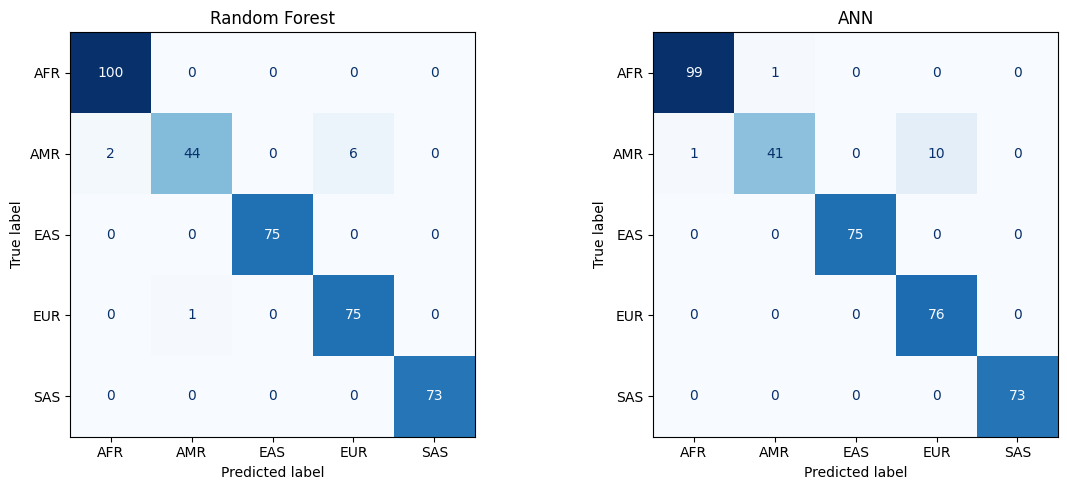

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, preds, title in zip(axes, [rf_test_pred, ann_test_pred], ["Random Forest", "ANN"]):
    cm = confusion_matrix(y_test, preds, labels=class_names)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_scores, ann_scores = [], []

for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
    # Random Forest, using the best settings found earlier
    rf_pipe = make_pipeline(
        StandardScaler(), PCA(n_components=N_COMPONENTS, random_state=42),
        RandomForestClassifier(**grid.best_params_, random_state=42, n_jobs=-1))
    rf_pipe.fit(X[tr], y[tr])
    rf_scores.append(f1_score(y[te], rf_pipe.predict(X[te]), average="macro"))

    # ANN
    sc = StandardScaler().fit(X[tr])
    pc = PCA(n_components=N_COMPONENTS, random_state=42).fit(sc.transform(X[tr]))
    Xtr, Xte = pc.transform(sc.transform(X[tr])), pc.transform(sc.transform(X[te]))
    ytr, yte = encoder.transform(y[tr]), encoder.transform(y[te])

    model = build_ann(N_COMPONENTS, len(class_names))
    model.fit(Xtr, ytr, validation_split=0.15, epochs=200, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                                       restore_best_weights=True)])
    ann_scores.append(f1_score(yte, np.argmax(model.predict(Xte, verbose=0), axis=1), average="macro"))
    print(f"Fold {fold}: RF = {rf_scores[-1]:.4f}, ANN = {ann_scores[-1]:.4f}")

print("\nRF  macro F1: {:.4f} +/- {:.4f}".format(np.mean(rf_scores), np.std(rf_scores)))
print("ANN macro F1: {:.4f} +/- {:.4f}".format(np.mean(ann_scores), np.std(ann_scores)))

Fold 1: RF = 0.9437, ANN = 0.9278
Fold 2: RF = 0.9677, ANN = 0.9528
Fold 3: RF = 0.9697, ANN = 0.9373
Fold 4: RF = 0.9657, ANN = 0.9518
Fold 5: RF = 0.9778, ANN = 0.9497

RF  macro F1: 0.9649 +/- 0.0114
ANN macro F1: 0.9439 +/- 0.0098


In [11]:
import joblib

OUT = "/content/drive/MyDrive/ancestry_project/models"
os.makedirs(OUT, exist_ok=True)

joblib.dump(scaler, f"{OUT}/scaler.joblib")
joblib.dump(pca, f"{OUT}/pca.joblib")
joblib.dump(rf, f"{OUT}/random_forest.joblib")
joblib.dump(encoder, f"{OUT}/label_encoder.joblib")
ann.save(f"{OUT}/ann_model.keras")

# training PCA coordinates, so the app can draw the background scatter plot
np.save(f"{OUT}/train_pcs.npy", X_train_pc)
np.save(f"{OUT}/train_labels.npy", y_train)

# a few test samples the app can use as a demo
np.save(f"{OUT}/demo_samples.npy", X_test[:20].astype(np.int8))
np.save(f"{OUT}/demo_labels.npy", y_test[:20])

print("Saved to", OUT)
print(os.listdir(OUT))

Saved to /content/drive/MyDrive/ancestry_project/models
['scaler.joblib', 'pca.joblib', 'random_forest.joblib', 'label_encoder.joblib', 'ann_model.keras', 'train_pcs.npy', 'train_labels.npy', 'demo_samples.npy', 'demo_labels.npy']
